### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

In [3]:
#Helper Functions: Evaluation Reports ( Confusion Matrix, Metrics, ROC and Precision-Recall )
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve)

def plot_confusion(cm, labels, ax, title="Confusion matrix"):
    ax.imshow(cm, cmap="Reds"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45 if len(labels) > 4 else 0, ha="right" if len(labels) > 4 else "center")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10 if len(labels) > 4 else 13,
                    color="white" if cm[i, j] > cm.max() / 2 else DARK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)

def report_binary(y_true, y_pred, y_score, name="model", labels=("negative", "positive"), plot=True):
    """Confusion matrix, ROC and Precision-Recall curves + a Series with the main metrics (positive class = 1)."""
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred), "MCC": matthews_corrcoef(y_true, y_pred),
               "ROC AUC": roc_auc_score(y_true, y_score), "PR AUC": average_precision_score(y_true, y_score)}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        plot_confusion(confusion_matrix(y_true, y_pred), list(labels), axes[0], f"Confusion matrix – {name}")
        fpr, tpr, _ = roc_curve(y_true, y_score)
        axes[1].plot(fpr, tpr, color=RED, lw=2.4, label=f"AUC = {metrics['ROC AUC']:.3f}"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--")
        axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
        p, r, _ = precision_recall_curve(y_true, y_score)
        axes[2].plot(r, p, color=DARK, lw=2.4, label=f"AP = {metrics['PR AUC']:.3f}"); axes[2].axhline(y_true.mean(), color=GRAY, ls="--")
        axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision–Recall curve"); axes[2].legend(loc="lower left")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)

def report_multiclass(y_true, y_pred, y_proba, labels, name="model", plot=True):
    """Confusion matrix, one-vs-rest ROC curves and per-class F1 + a Series with the main metrics."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    k = len(labels)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
               "macro recall": recall_score(y_true, y_pred, average="macro"), "macro F1": f1_score(y_true, y_pred, average="macro"),
               "MCC": matthews_corrcoef(y_true, y_pred), "ROC AUC (ovr)": roc_auc_score(y_true, y_proba, multi_class="ovr"),
               "log loss": log_loss(y_true, y_proba, labels=list(range(k)))}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        plot_confusion(confusion_matrix(y_true, y_pred, labels=list(range(k))), list(labels), axes[0], f"Confusion matrix – {name}")
        cmap = plt.get_cmap("tab10")
        for c in range(k):
            fpr, tpr, _ = roc_curve((y_true == c).astype(int), y_proba[:, c])
            axes[1].plot(fpr, tpr, color=cmap(c), lw=1.6, label=f"{labels[c]}")
        axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
        axes[1].set_title(f"ROC one-vs-rest (macro AUC = {metrics['ROC AUC (ovr)']:.3f})"); axes[1].legend(fontsize=7, ncol=2 if k > 5 else 1, loc="lower right")
        f1s = f1_score(y_true, y_pred, average=None)
        axes[2].bar(range(k), f1s, color=RED, width=0.65); axes[2].set_xticks(range(k)); axes[2].set_xticklabels(labels, rotation=45 if k > 4 else 0, ha="right" if k > 4 else "center")
        axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("F1"); axes[2].set_title("F1 per class")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)
def annotate_heatmap(ax, mat, fmt="{:.2f}"):
    """Write the values on an imshow heat map with a readable text color."""
    mat = np.asarray(mat, dtype=float)
    lo, hi = np.nanmin(mat), np.nanmax(mat)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", color="white" if (not np.isnan(v) and v > (lo + hi) / 2) else DARK)

### **1. Types of Artificial Neural Networks**

| Network | Learning | Typical task | Evaluated with |
|---|---|---|---|
| **MLP** | supervised (backpropagation) | classification / regression | accuracy, confusion matrix, ROC, loss curves |
| **SOM** (Kohonen) | unsupervised, competitive | visualisation, clustering | quantization & topographic error, U-matrix |
| **Hopfield** | Hebbian, associative memory | pattern recall, denoising | recall rate × noise, capacity, energy |
| **CNN** | supervised | images | accuracy, confusion matrix, learned filters |
| **LSTM** | supervised, through time (BPTT) | sequences, forecasting | RMSE / MAE / R², baselines |
| **GAN** | adversarial (two networks) | data generation | Wasserstein distance, mode coverage, discriminability |

Except for the MLP (scikit-learn), every network is **written from scratch in NumPy**, including backpropagation, so you can see what the frameworks hide. **Gradient checks** confirm the hand-written derivatives.

### **2. Dataset: Handwritten Digits**

1 797 images of **8 × 8 pixels**, 10 classes. Split: **test 30 %**, then **validation 15 %** of the rest (used to monitor training).

fit: (1068, 64) | validation: (189, 64) | test: (540, 64)


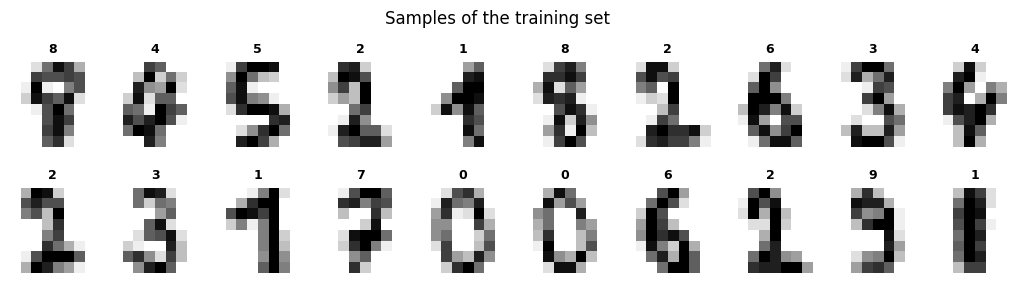

In [4]:
#Load the Digits Dataset and Split ( Train / Validation / Test )
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X_all, y_all = digits.data / 16.0, digits.target                                         # pixels scaled to [0, 1]
X_rest, X_te, y_rest, y_te = train_test_split(X_all, y_all, test_size=0.30, random_state=RANDOM_STATE, stratify=y_all)
X_fit, X_val, y_fit, y_val = train_test_split(X_rest, y_rest, test_size=0.15, random_state=RANDOM_STATE, stratify=y_rest)
DIGITS = [str(d) for d in range(10)]
print("fit:", X_fit.shape, "| validation:", X_val.shape, "| test:", X_te.shape)

fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(X_fit[k].reshape(8, 8), cmap="gray_r"); ax.set_title(str(y_fit[k]), fontsize=9); ax.axis("off")
plt.suptitle("Samples of the training set", y=1.02); plt.show()

### **3. Multilayer Perceptron (MLP)**

Layers of neurons $h = \phi(Wx + b)$ trained by **backpropagation** and **gradient descent** (here, Adam) to minimise the cross-entropy:

$$\mathcal{L} = -\frac{1}{N}\sum_i \log p_\theta(y_i \mid x_i)$$

We train one epoch at a time (`partial_fit`) to follow the **loss** and the **validation accuracy**.

parameters: 4810 | final train accuracy 1.000 | validation accuracy 0.989


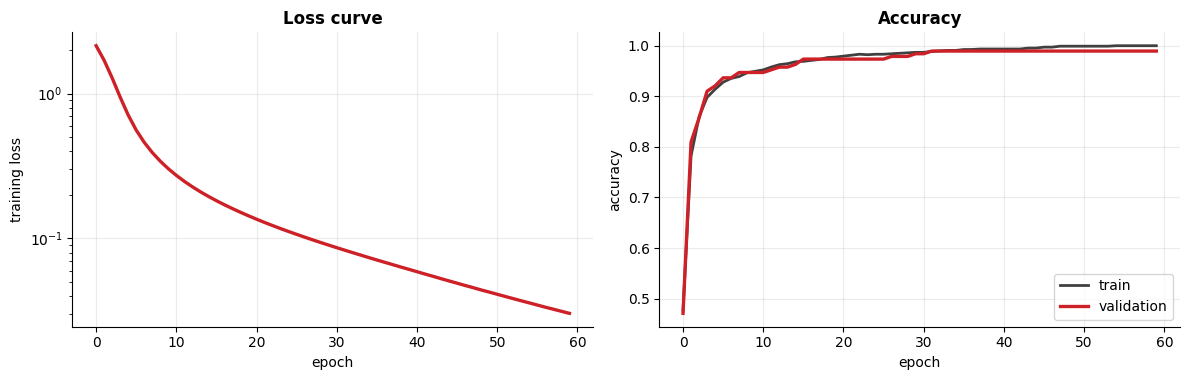

In [5]:
#Train an MLP ( 64 Hidden ReLU Neurons ) Epoch by Epoch
from sklearn.neural_network import MLPClassifier
from scipy.special import expit

def train_mlp(hidden=(64,), activation="relu", alpha=1e-4, epochs=60, seed=RANDOM_STATE):
    mlp = MLPClassifier(hidden_layer_sizes=hidden, activation=activation, alpha=alpha, solver="adam", batch_size=32, learning_rate_init=1e-3, random_state=seed)
    hist = {"loss": [], "train acc": [], "val acc": []}
    for _ in range(epochs):
        mlp.partial_fit(X_fit, y_fit, classes=np.arange(10))
        hist["loss"].append(mlp.loss_); hist["train acc"].append(mlp.score(X_fit, y_fit)); hist["val acc"].append(mlp.score(X_val, y_val))
    return mlp, hist

mlp, hist = train_mlp()
n_params = sum(c.size for c in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
print(f"parameters: {n_params} | final train accuracy {hist['train acc'][-1]:.3f} | validation accuracy {hist['val acc'][-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].plot(hist["loss"], color=RED, lw=2.4); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss"); axes[0].set_yscale("log"); axes[0].set_title("Loss curve")
axes[1].plot(hist["train acc"], color=DARK, lw=2, label="train"); axes[1].plot(hist["val acc"], color=RED, lw=2.4, label="validation"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()

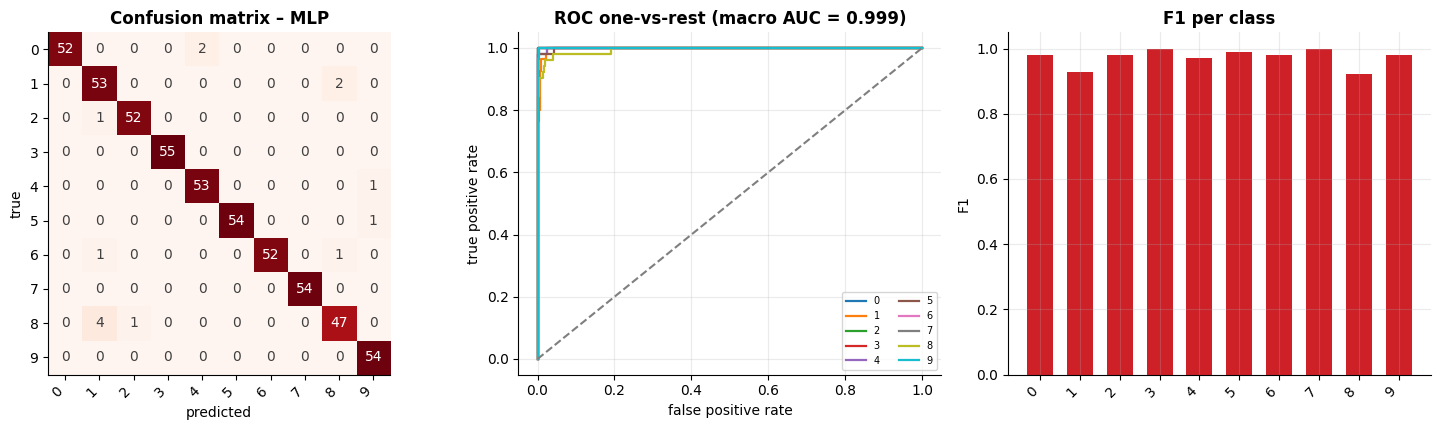

,accuracy,balanced acc.,macro precision,macro recall,macro F1,MCC,ROC AUC (ovr),log loss
MLP,0.974,0.974,0.975,0.974,0.974,0.971,0.999,0.1


In [6]:
#Evaluate the MLP on the Test Set ( Confusion Matrix, One-vs-Rest ROC, F1 per Class )
results = {}
results["MLP"] = report_multiclass(y_te, mlp.predict(X_te), mlp.predict_proba(X_te), DIGITS, "MLP")
results["MLP"].to_frame().T

#### **MLP-Specific Metrics**

How the **architecture** (hidden neurons, depth), the **activation function** and the **regularisation** (L2 penalty α) change the result.

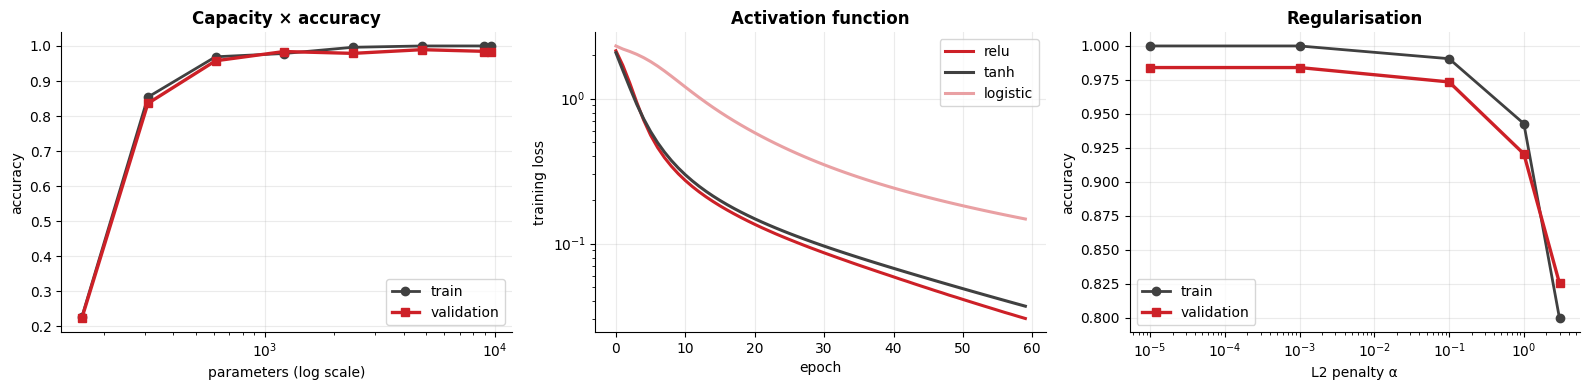

,hidden layers,parameters,train acc,val acc
0,"(2,)",160,0.226,0.222
1,"(4,)",310,0.854,0.836
2,"(8,)",610,0.969,0.958
3,"(16,)",1210,0.978,0.984
4,"(32,)",2410,0.996,0.979
5,"(64,)",4810,1.000,0.989
6,"(128,)",9610,1.000,0.984
7,"(64, 64)",8970,1.000,0.984


In [7]:
#Architecture, Activation and Regularisation Sweeps ( Validation Accuracy and Number of Parameters )
rows = []
for hidden in [(2,), (4,), (8,), (16,), (32,), (64,), (128,), (64, 64)]:
    m, h = train_mlp(hidden)
    rows.append({"hidden layers": str(hidden), "parameters": sum(c.size for c in m.coefs_) + sum(b.size for b in m.intercepts_), "train acc": h["train acc"][-1], "val acc": h["val acc"][-1]})
arch = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(arch["parameters"], arch["train acc"], marker="o", color=DARK, lw=2, label="train"); axes[0].plot(arch["parameters"], arch["val acc"], marker="s", color=RED, lw=2.4, label="validation")
axes[0].set_xscale("log"); axes[0].set_xlabel("parameters (log scale)"); axes[0].set_ylabel("accuracy"); axes[0].set_title("Capacity × accuracy"); axes[0].legend()
for act, color in zip(["relu", "tanh", "logistic"], [RED, DARK, SOFT]):
    _, h = train_mlp((64,), activation=act); axes[1].plot(h["loss"], color=color, lw=2.2, label=act)
axes[1].set_yscale("log"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("training loss"); axes[1].set_title("Activation function"); axes[1].legend()
alphas = [1e-5, 1e-3, 1e-1, 1, 3]
reg = [train_mlp((128,), alpha=a)[1] for a in alphas]
axes[2].plot(alphas, [h["train acc"][-1] for h in reg], marker="o", color=DARK, lw=2, label="train"); axes[2].plot(alphas, [h["val acc"][-1] for h in reg], marker="s", color=RED, lw=2.4, label="validation")
axes[2].set_xscale("log"); axes[2].set_xlabel("L2 penalty α"); axes[2].set_ylabel("accuracy"); axes[2].set_title("Regularisation"); axes[2].legend()
plt.tight_layout(); plt.show()
arch.round(3)

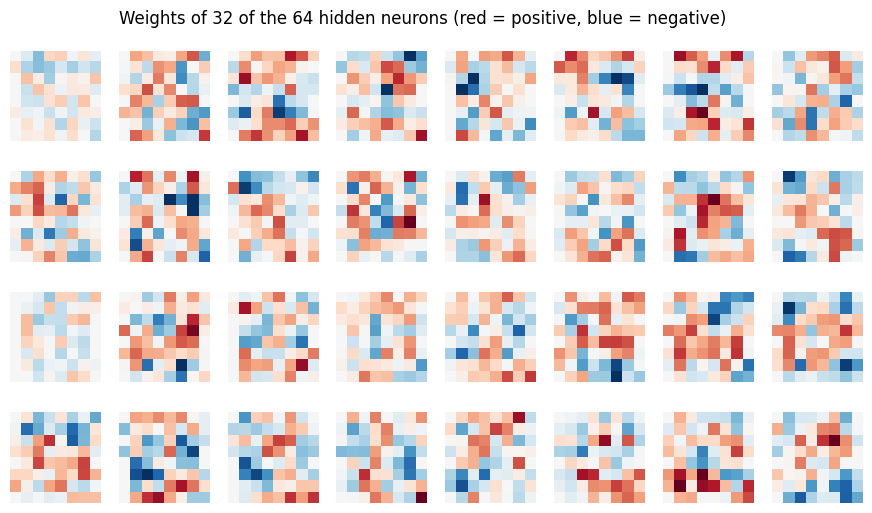

In [8]:
#What Did the Hidden Neurons Learn? ( First-Layer Weights as 8x8 Images )
fig, axes = plt.subplots(4, 8, figsize=(11, 6))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(mlp.coefs_[0][:, k].reshape(8, 8), cmap="RdBu_r", vmin=-0.6, vmax=0.6); ax.axis("off")
plt.suptitle("Weights of 32 of the 64 hidden neurons (red = positive, blue = negative)", y=0.94); plt.show()

### **4. Self-Organizing Map (SOM)**

A grid of neurons, each with a **weight vector**. For each sample $x$:

1. **Best matching unit (BMU):** the neuron with the closest weights
2. **Update** the BMU **and its neighbours**: $w_j \leftarrow w_j + \eta(t)\, h_{j,\text{BMU}}(t)\,(x - w_j)$, with $h = e^{-d^2 / 2\sigma(t)^2}$

The learning rate $\eta$ and the neighbourhood radius $\sigma$ **shrink** over time: the map first orders itself globally, then fine-tunes. **No labels are used for training.**

In [9]:
#SOM Implementation from Scratch ( Online Training, Gaussian Neighbourhood, Quantization and Topographic Errors, U-Matrix )
class SOM:
    def __init__(self, rows, cols, seed=0):
        self.rows, self.cols, self.seed = rows, cols, seed
        self.grid = np.array([(r, c) for r in range(rows) for c in range(cols)], dtype=float)

    def fit(self, X, epochs=30, lr0=0.5, sigma0=None):
        rng = np.random.default_rng(self.seed)
        sigma0 = sigma0 or max(self.rows, self.cols) / 2
        self.W = X[rng.choice(len(X), len(self.grid), replace=False)].copy()                 # initialise with random samples
        self.qe_history_ = []
        for ep in range(epochs):
            frac = ep / epochs
            lr, sigma = lr0 * (1 - frac) + 0.01, sigma0 * np.exp(-3 * frac) + 0.5
            for x in X[rng.permutation(len(X))]:
                bmu = np.argmin(((self.W - x) ** 2).sum(axis=1))
                h = np.exp(-((self.grid - self.grid[bmu]) ** 2).sum(axis=1) / (2 * sigma ** 2))
                self.W += lr * h[:, None] * (x - self.W)
            self.qe_history_.append(self.quantization_error(X))
        return self

    def _dist(self, X):
        return np.sqrt(((X[:, None, :] - self.W[None, :, :]) ** 2).sum(axis=2))

    def bmu(self, X):
        return self._dist(X).argmin(axis=1)

    def quantization_error(self, X):                                                          # mean distance to the BMU
        return self._dist(X).min(axis=1).mean()

    def topographic_error(self, X):                                                           # share of samples whose 2 best units are not neighbours
        two = np.argsort(self._dist(X), axis=1)[:, :2]
        gap = np.abs(self.grid[two[:, 0]] - self.grid[two[:, 1]]).max(axis=1)
        return (gap > 1).mean()

    def umatrix(self):
        U = np.zeros((self.rows, self.cols))
        for r in range(self.rows):
            for c in range(self.cols):
                nb = [(r + dr, c + dc) for dr in (-1, 0, 1) for dc in (-1, 0, 1) if (dr or dc) and 0 <= r + dr < self.rows and 0 <= c + dc < self.cols]
                U[r, c] = np.mean([np.linalg.norm(self.W[r * self.cols + c] - self.W[a * self.cols + b]) for a, b in nb])
        return U

som = SOM(10, 10, seed=RANDOM_STATE).fit(X_fit, epochs=30)
print(f"quantization error: train {som.quantization_error(X_fit):.3f} | test {som.quantization_error(X_te):.3f} | topographic error (test): {som.topographic_error(X_te):.3f}")

quantization error: train 1.283 | test 1.337 | topographic error (test): 0.020


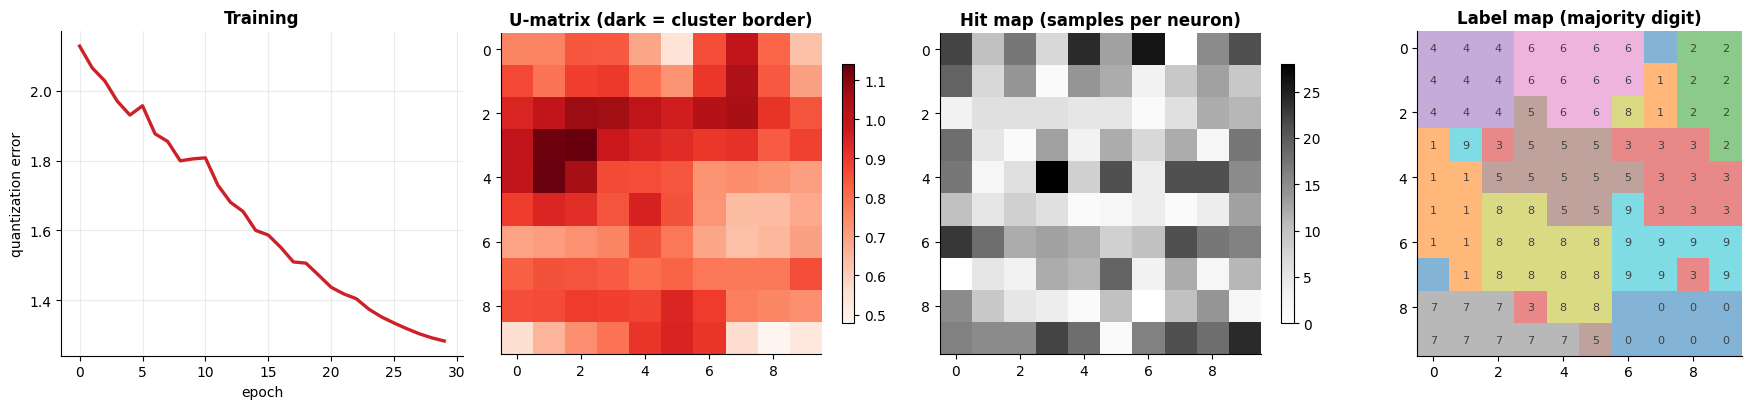

neuron purity (share of samples that match the majority label of their neuron): 0.949 | empty neurons: 3 of 100


In [10]:
#SOM Visualisations: Training Curve, U-Matrix, Hit Map and Label Map
bmu_fit = som.bmu(X_fit)
hits = np.bincount(bmu_fit, minlength=100).reshape(10, 10)
counts = np.zeros((100, 10))
np.add.at(counts, (bmu_fit, y_fit), 1)
label_map = counts.argmax(axis=1).reshape(10, 10)
purity = counts.max(axis=1).sum() / len(y_fit)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
axes[0].plot(som.qe_history_, color=RED, lw=2.4); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("quantization error"); axes[0].set_title("Training")
im = axes[1].imshow(som.umatrix(), cmap="Reds"); axes[1].grid(False); axes[1].set_title("U-matrix (dark = cluster border)"); fig.colorbar(im, ax=axes[1], shrink=0.8)
im = axes[2].imshow(hits, cmap="Greys"); axes[2].grid(False); axes[2].set_title("Hit map (samples per neuron)"); fig.colorbar(im, ax=axes[2], shrink=0.8)
cmap = plt.get_cmap("tab10")
axes[3].imshow(label_map, cmap="tab10", vmin=0, vmax=9, alpha=0.55); axes[3].grid(False); axes[3].set_title("Label map (majority digit)")
for r in range(10):
    for c in range(10):
        if hits[r, c]:
            axes[3].text(c, r, label_map[r, c], ha="center", va="center", fontsize=8, color=DARK)
plt.tight_layout(); plt.show()
print(f"neuron purity (share of samples that match the majority label of their neuron): {purity:.3f} | empty neurons: {(hits == 0).sum()} of 100")

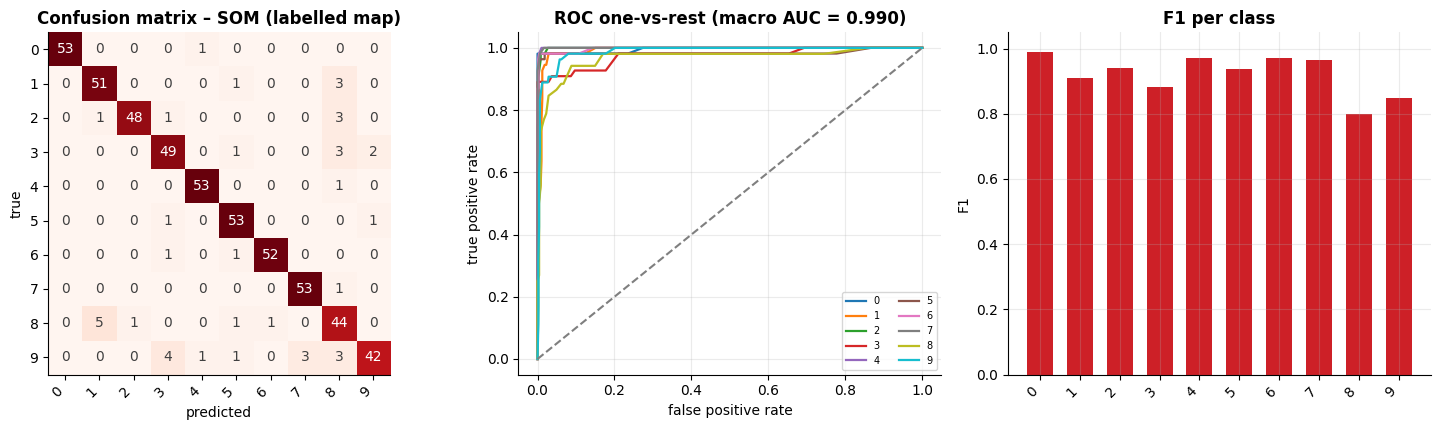

,accuracy,balanced acc.,macro precision,macro recall,macro F1,MCC,ROC AUC (ovr),log loss
SOM (labelled map),0.922,0.922,0.925,0.922,0.922,0.914,0.99,0.318


In [11]:
#Use the Labelled Map as a Classifier ( Class Distribution of the BMU ) and Evaluate on the Test Set
prior = np.bincount(y_fit, minlength=10) / len(y_fit)
class_dist = (counts + 0.1 * prior) / (counts.sum(axis=1, keepdims=True) + 0.1)               # empty neurons fall back to the prior
proba_som = class_dist[som.bmu(X_te)]
results["SOM"] = report_multiclass(y_te, proba_som.argmax(axis=1), proba_som, DIGITS, "SOM (labelled map)")
results["SOM"].to_frame().T

#### **SOM-Specific Metrics**

**Quantization error** (how well the map represents the data) × **topographic error** (how well it **preserves the topology**) as a function of the **map size**.

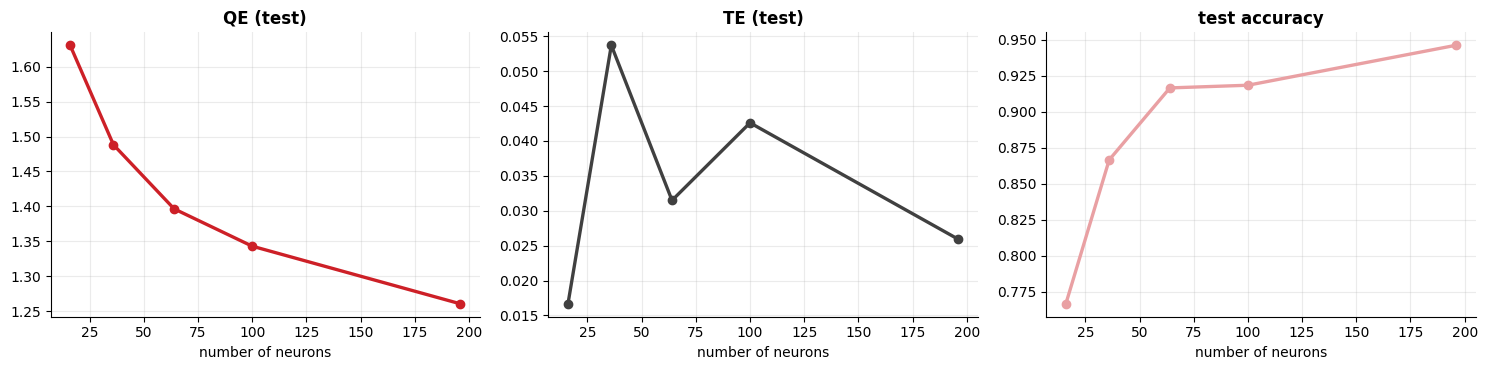

,map,neurons,QE (test),TE (test),test accuracy
0,4x4,16,1.630,0.017,0.767
1,6x6,36,1.488,0.054,0.867
2,8x8,64,1.397,0.031,0.917
3,10x10,100,1.343,0.043,0.919
4,14x14,196,1.261,0.026,0.946


In [12]:
#Map Size Sweep: Quantization Error, Topographic Error and Test Accuracy
rows = []
for side in [4, 6, 8, 10, 14]:
    s = SOM(side, side, seed=RANDOM_STATE).fit(X_fit, epochs=20)
    cnt = np.zeros((side * side, 10)); np.add.at(cnt, (s.bmu(X_fit), y_fit), 1)
    dist = (cnt + 0.1 * prior) / (cnt.sum(axis=1, keepdims=True) + 0.1)
    rows.append({"map": f"{side}x{side}", "neurons": side * side, "QE (test)": s.quantization_error(X_te), "TE (test)": s.topographic_error(X_te), "test accuracy": (dist[s.bmu(X_te)].argmax(axis=1) == y_te).mean()})
sweep = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, color in zip(axes, ["QE (test)", "TE (test)", "test accuracy"], [RED, DARK, SOFT]):
    ax.plot(sweep["neurons"], sweep[col], marker="o", color=color, lw=2.4); ax.set_xlabel("number of neurons"); ax.set_title(col)
plt.tight_layout(); plt.show()
sweep.round(3)

### **5. Hopfield Network**

A **recurrent** network of $N$ binary neurons ($\pm 1$) that works as an **associative memory**:

* **Storage:** *Hebb* rule $W = \frac{1}{N}\sum_{\mu} \xi^\mu (\xi^\mu)^T$ (zero diagonal) or the **pseudo-inverse** rule $W = \Xi^T (\Xi \Xi^T)^{-1} \Xi$
* **Recall:** neurons are updated one by one, $s_i \leftarrow \text{sign}(\sum_j W_{ij} s_j)$, until the state stops changing
* **Energy:** $E = -\frac{1}{2} s^T W s$ never increases → the state falls into an **attractor** (ideally a stored pattern)
* **Capacity:** Hebb stores about $0.138\,N$ **random** patterns and fails with **correlated** ones (like digits); the pseudo-inverse rule handles correlated patterns up to $K < N$

In [13]:
#Hopfield Network from Scratch ( Hebb and Pseudo-Inverse Storage, Asynchronous Recall, Energy )
class Hopfield:
    def __init__(self, rule="hebb"):
        self.rule = rule

    def fit(self, patterns):
        P = np.asarray(patterns, float)
        self.n_ = P.shape[1]
        if self.rule == "hebb":
            self.W = P.T @ P / self.n_
            np.fill_diagonal(self.W, 0)
        else:                                                                                   # pseudo-inverse (projection) rule
            self.W = P.T @ np.linalg.inv(P @ P.T) @ P
        return self

    def energy(self, s):
        return -0.5 * s @ self.W @ s

    def recall(self, s, rng, max_sweeps=30):
        s = s.astype(float).copy()
        states, energies = [s.copy()], [self.energy(s)]
        for _ in range(max_sweeps):
            changed = False
            for i in rng.permutation(self.n_):
                new = 1.0 if self.W[i] @ s >= 0 else -1.0
                if new != s[i]:
                    s[i], changed = new, True
            states.append(s.copy()); energies.append(self.energy(s))
            if not changed:
                break
        return s, np.array(energies), states

#Stored patterns: the average image of each digit, binarised to -1 / +1
protos = np.array([X_fit[y_fit == d].mean(axis=0) for d in range(10)])
bin_protos = np.where(protos > 0.45, 1.0, -1.0)
print("neurons:", bin_protos.shape[1], "| mean |correlation| between different digit prototypes:", round(float(np.abs(np.corrcoef(bin_protos)[np.triu_indices(10, 1)]).mean()), 3), "(random patterns: ≈ 0.1)")

neurons: 64 | mean |correlation| between different digit prototypes: 0.511 (random patterns: ≈ 0.1)


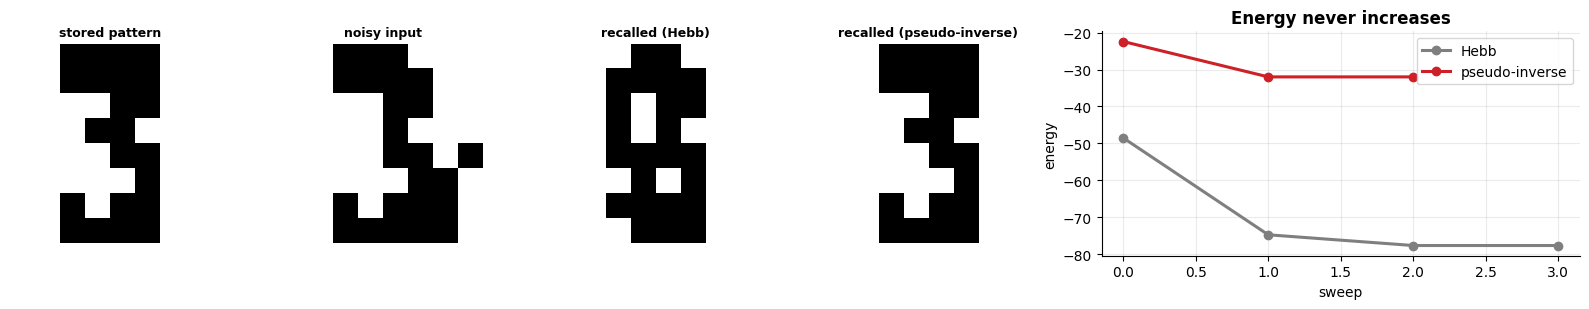

          Hebb: overlap with the stored digit = 0.688
pseudo-inverse: overlap with the stored digit = 1.000


In [14]:
#Recall from a Noisy Digit with Each Storage Rule ( 5 Stored Digits, 6 Flipped Pixels ) and the Energy Descent
rng = np.random.default_rng(RANDOM_STATE)
K, target = 5, 3
nets = {"Hebb": Hopfield("hebb").fit(bin_protos[:K]), "pseudo-inverse": Hopfield("pinv").fit(bin_protos[:K])}
noisy = bin_protos[target].copy(); noisy[rng.choice(64, 6, replace=False)] *= -1
out = {name: n.recall(noisy, rng) for name, n in nets.items()}

fig, axes = plt.subplots(1, 5, figsize=(16, 3.2), gridspec_kw={"width_ratios": [1, 1, 1, 1, 2.4]})
for ax, img, title in zip(axes[:4], [bin_protos[target], noisy, out["Hebb"][0], out["pseudo-inverse"][0]],
                          ["stored pattern", "noisy input", "recalled (Hebb)", "recalled (pseudo-inverse)"]):
    ax.imshow(img.reshape(8, 8), cmap="gray_r"); ax.set_title(title, fontsize=9); ax.axis("off")
for (name, (_, energies, _)), color in zip(out.items(), [GRAY, RED]):
    axes[4].plot(energies, marker="o", color=color, lw=2.2, label=name)
axes[4].set_xlabel("sweep"); axes[4].set_ylabel("energy"); axes[4].set_title("Energy never increases"); axes[4].legend()
plt.tight_layout(); plt.show()
for name, (final, _, _) in out.items():
    print(f"{name:>14}: overlap with the stored digit = {final @ bin_protos[target] / 64:.3f}")

Hebb's rule **fails** here: the digit prototypes are **correlated** (cross-talk), so even the stored patterns are not stable. The **pseudo-inverse** rule removes the cross-talk.

#### **Hopfield-Specific Metrics**

* **Recall rate** as a function of the **noise level** and of the **number of stored patterns**
* **Capacity** for random patterns (share of **stable** stored patterns × load $K/N$) – the classical **0.138 N** limit of Hebb
* **Confusion matrix** of the recalled pattern (the network used as a classifier), including **spurious** states

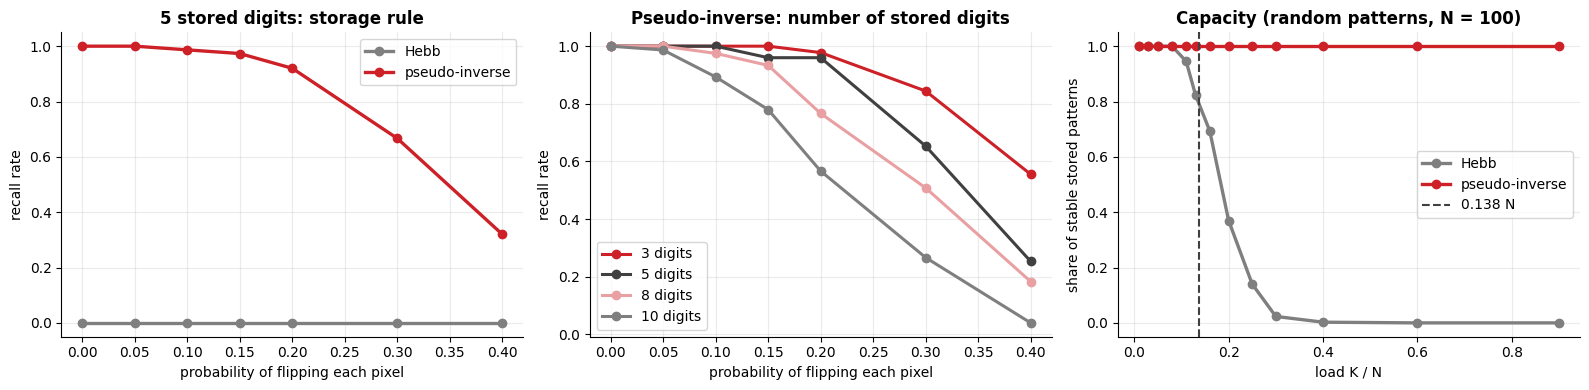

noise,0.00,0.05,0.10,0.15,0.20,0.30,0.40
"Hebb, 5 digits",0.0,0.00,0.00,0.00,0.00,0.00,0.00
"pinv, 3 digits",1.0,1.00,1.00,1.00,0.98,0.84,0.56
"pinv, 5 digits",1.0,1.00,1.00,0.96,0.96,0.65,0.25
"pinv, 8 digits",1.0,1.00,0.98,0.93,0.77,0.51,0.18
"pinv, 10 digits",1.0,0.99,0.89,0.78,0.57,0.27,0.04


In [15]:
#Recall Rate vs Noise ( Hebb vs Pseudo-Inverse, and Number of Stored Digits ) and Storage Capacity ( Random Patterns, N = 100 )
rng = np.random.default_rng(RANDOM_STATE)
noise_levels = [0.0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40]

def recall_rate(rule, K, p, trials=15):
    net_k, ok, n = Hopfield(rule).fit(bin_protos[:K]), 0, 0
    for mu in range(K):
        for _ in range(trials):
            out = net_k.recall(bin_protos[mu] * np.where(rng.random(64) < p, -1, 1), rng)[0]
            ok += (out @ bin_protos[mu] / 64) > 0.95; n += 1
    return ok / n

rule_curves = {r: [recall_rate(r, 5, p) for p in noise_levels] for r in ("hebb", "pinv")}
k_curves = {K: [recall_rate("pinv", K, p) for p in noise_levels] for K in (3, 5, 8, 10)}

N_rand, loads = 100, [1, 3, 5, 8, 11, 13, 16, 20, 25, 30, 40, 60, 90]
stable = {r: [] for r in ("hebb", "pinv")}
for rule in stable:
    for K in loads:
        ok = []
        for _ in range(10):
            P = rng.choice([-1.0, 1.0], size=(K, N_rand)); W = Hopfield(rule).fit(P).W
            ok.append(np.mean([(np.where(W @ p >= 0, 1.0, -1.0) == p).all() for p in P]))                  # one-step stability of every stored pattern
        stable[rule].append(np.mean(ok))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for (r, rates), color, name in zip(rule_curves.items(), [GRAY, RED], ["Hebb", "pseudo-inverse"]):
    axes[0].plot(noise_levels, rates, marker="o", color=color, lw=2.4, label=name)
axes[0].set_xlabel("probability of flipping each pixel"); axes[0].set_ylabel("recall rate"); axes[0].set_title("5 stored digits: storage rule"); axes[0].legend()
for (K, rates), color in zip(k_curves.items(), [RED, DARK, SOFT, GRAY]):
    axes[1].plot(noise_levels, rates, marker="o", color=color, lw=2.2, label=f"{K} digits")
axes[1].set_xlabel("probability of flipping each pixel"); axes[1].set_ylabel("recall rate"); axes[1].set_title("Pseudo-inverse: number of stored digits"); axes[1].legend()
for rule, color, name in zip(stable, [GRAY, RED], ["Hebb", "pseudo-inverse"]):
    axes[2].plot(np.array(loads) / N_rand, stable[rule], marker="o", color=color, lw=2.4, label=name)
axes[2].axvline(0.138, color=DARK, ls="--", label="0.138 N"); axes[2].set_xlabel("load K / N"); axes[2].set_ylabel("share of stable stored patterns"); axes[2].set_title("Capacity (random patterns, N = 100)"); axes[2].legend()
plt.tight_layout(); plt.show()
pd.DataFrame({**{f"Hebb, 5 digits": rule_curves["hebb"]}, **{f"pinv, {K} digits": r for K, r in k_curves.items()}}, index=noise_levels).rename_axis("noise").round(2).T

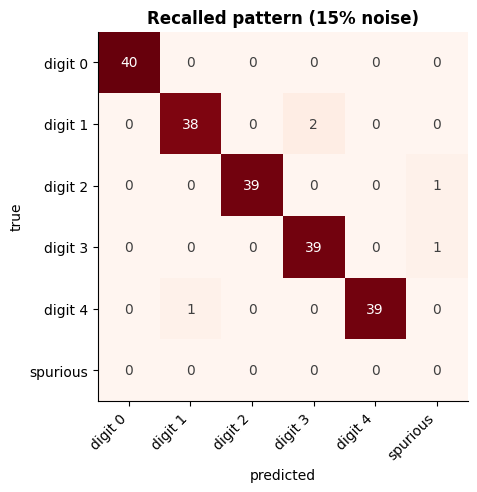

recall accuracy: 0.975 | spurious states: 1.0%


In [16]:
#The Hopfield Network as a Classifier ( 5 Stored Digits, Pseudo-Inverse Rule, 15% Noise ): Confusion Matrix Including Spurious States
rng = np.random.default_rng(RANDOM_STATE)
K = 5
net5 = Hopfield("pinv").fit(bin_protos[:K])
true_idx, pred_idx = [], []
for mu in range(K):
    for _ in range(40):
        out = net5.recall(bin_protos[mu] * np.where(rng.random(64) < 0.15, -1, 1), rng)[0]
        ov = bin_protos[:K] @ out / 64
        true_idx.append(mu); pred_idx.append(int(ov.argmax()) if ov.max() > 0.9 else K)               # K = spurious / mixed state
labels_h = [f"digit {d}" for d in range(K)] + ["spurious"]
cm = confusion_matrix(true_idx, pred_idx, labels=list(range(K + 1)))
fig, ax = plt.subplots(figsize=(5.8, 4.8)); plot_confusion(cm, labels_h, ax, "Recalled pattern (15% noise)"); plt.show()
print(f"recall accuracy: {np.mean(np.array(true_idx) == np.array(pred_idx)):.3f} | spurious states: {np.mean(np.array(pred_idx) == K):.1%}")

### **6. Convolutional Neural Network (CNN)**

The same **small filters** slide over the image (**weight sharing**), detecting local patterns wherever they appear:

`image 8×8` ⟶ **Conv 3×3 (8 filters)** ⟶ ReLU ⟶ **Max-pool 2×2** ⟶ **Dense (10)** ⟶ softmax

* Convolution as a matrix product (**im2col**): each 3×3 patch is a row
* Backpropagation through the **max-pool** (gradient goes to the maximum), the **ReLU** and the **convolution**
* Far **fewer parameters** than a dense network over the whole image

In [17]:
#CNN from Scratch ( Convolution, ReLU, Max-Pooling, Dense, Softmax, Hand-Written Backpropagation and Adam )
from numpy.lib.stride_tricks import sliding_window_view

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

class TinyCNN:
    def __init__(self, n_filters=8, n_classes=10, seed=0):
        rng, F = np.random.default_rng(seed), n_filters
        self.F = F
        self.p = {"Wc": rng.normal(0, np.sqrt(2 / 9), (9, F)), "bc": np.zeros(F),
                  "Wd": rng.normal(0, np.sqrt(2 / (9 * F)), (9 * F, n_classes)), "bd": np.zeros(n_classes)}
        self.m = {k: np.zeros_like(v) for k, v in self.p.items()}; self.v = {k: np.zeros_like(v) for k, v in self.p.items()}; self.t = 0

    def forward(self, X):                                                                     # X: (N, 8, 8)
        N, F = len(X), self.F
        patches = sliding_window_view(X, (3, 3), axis=(1, 2)).reshape(N * 36, 9)               # im2col: every 3x3 patch is a row
        conv = (patches @ self.p["Wc"] + self.p["bc"]).reshape(N, 6, 6, F)
        blocks = np.maximum(conv, 0).reshape(N, 3, 2, 3, 2, F)                                 # ReLU, then 2x2 blocks
        pooled = blocks.max(axis=(2, 4))
        flat = pooled.reshape(N, -1)
        self.cache = (patches, conv, blocks, pooled, flat)
        return flat @ self.p["Wd"] + self.p["bd"]

    def loss_and_grads(self, X, y):
        logits = self.forward(X)
        patches, conv, blocks, pooled, flat = self.cache
        N, F = len(y), self.F
        prob = softmax(logits)
        loss = -np.log(prob[np.arange(N), y] + 1e-12).mean()
        dlog = prob.copy(); dlog[np.arange(N), y] -= 1; dlog /= N
        g = {"Wd": flat.T @ dlog, "bd": dlog.sum(axis=0)}
        dpooled = (dlog @ self.p["Wd"].T).reshape(N, 3, 3, F)
        mask = blocks == pooled[:, :, None, :, None, :]                                        # where the maximum was
        mask = mask / mask.sum(axis=(2, 4), keepdims=True)
        dact = (mask * dpooled[:, :, None, :, None, :]).reshape(N, 6, 6, F)
        dconv = (dact * (conv > 0)).reshape(N * 36, F)                                         # ReLU backward
        g["Wc"], g["bc"] = patches.T @ dconv, dconv.sum(axis=0)
        return loss, g

    def step(self, g, lr=0.003):
        self.t += 1
        for k in self.p:
            self.m[k] = 0.9 * self.m[k] + 0.1 * g[k]; self.v[k] = 0.999 * self.v[k] + 0.001 * g[k] ** 2
            self.p[k] -= lr * (self.m[k] / (1 - 0.9 ** self.t)) / (np.sqrt(self.v[k] / (1 - 0.999 ** self.t)) + 1e-8)

    def predict_proba(self, X):
        return softmax(self.forward(X))

    def n_params(self):
        return sum(v.size for v in self.p.values())

imgs_fit, imgs_val, imgs_te = X_fit.reshape(-1, 8, 8), X_val.reshape(-1, 8, 8), X_te.reshape(-1, 8, 8)
cnn = TinyCNN(seed=RANDOM_STATE)
print("CNN parameters:", cnn.n_params(), "| MLP (64 hidden) parameters:", n_params)

CNN parameters: 810 | MLP (64 hidden) parameters: 4810


In [18]:
#Gradient Check: Hand-Written Backpropagation vs Numerical Derivatives ( Central Differences )
rng = np.random.default_rng(1)
check = TinyCNN(seed=3)
check.p["bc"], check.p["bd"] = rng.normal(0, 0.1, 8), rng.normal(0, 0.1, 10)             # non-zero biases: with all-zero patches and bias 0 the ReLU sits exactly on its kink
xb, yb = imgs_fit[:6], y_fit[:6]
_, grads = check.loss_and_grads(xb, yb)
worst = 0.0
for k in check.p:
    for _ in range(8):
        idx = tuple(rng.integers(s) for s in check.p[k].shape)
        old = check.p[k][idx]
        check.p[k][idx] = old + 1e-6; lp = check.loss_and_grads(xb, yb)[0]
        check.p[k][idx] = old - 1e-6; lm = check.loss_and_grads(xb, yb)[0]
        check.p[k][idx] = old
        num, ana = (lp - lm) / 2e-6, grads[k][idx]
        worst = max(worst, abs(num - ana) / max(1e-8, abs(num) + abs(ana)))
print(f"worst relative error between analytical and numerical gradients: {worst:.1e}  (≈ 1e-6 or less = correct)")

worst relative error between analytical and numerical gradients: 1.5e-08  (≈ 1e-6 or less = correct)


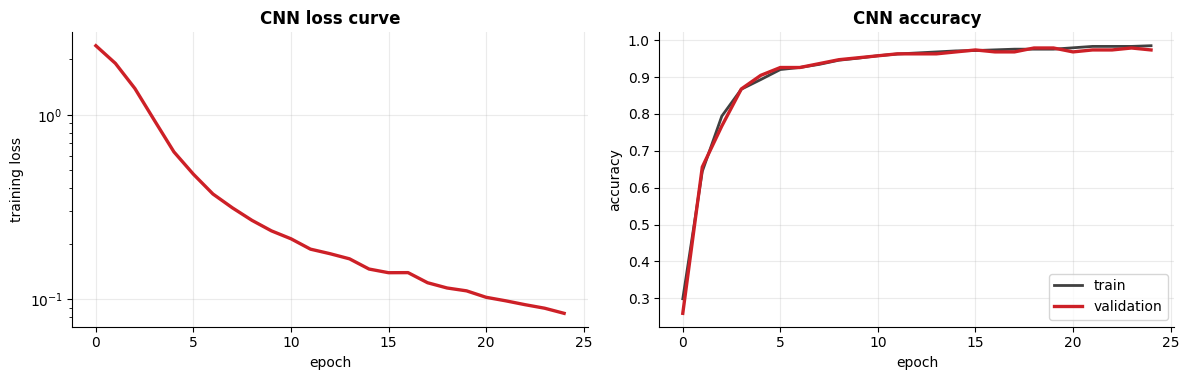

In [19]:
#Train the CNN ( 25 Epochs, Mini-Batches of 32, Adam )
rng = np.random.default_rng(RANDOM_STATE)
hist_cnn = {"loss": [], "train acc": [], "val acc": []}
for epoch in range(25):
    perm = rng.permutation(len(y_fit)); losses = []
    for k in range(0, len(perm), 32):
        b = perm[k:k + 32]
        loss, g = cnn.loss_and_grads(imgs_fit[b], y_fit[b]); cnn.step(g); losses.append(loss)
    hist_cnn["loss"].append(np.mean(losses))
    hist_cnn["train acc"].append((cnn.predict_proba(imgs_fit).argmax(axis=1) == y_fit).mean()); hist_cnn["val acc"].append((cnn.predict_proba(imgs_val).argmax(axis=1) == y_val).mean())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].plot(hist_cnn["loss"], color=RED, lw=2.4); axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss"); axes[0].set_title("CNN loss curve")
axes[1].plot(hist_cnn["train acc"], color=DARK, lw=2, label="train"); axes[1].plot(hist_cnn["val acc"], color=RED, lw=2.4, label="validation"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("CNN accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()

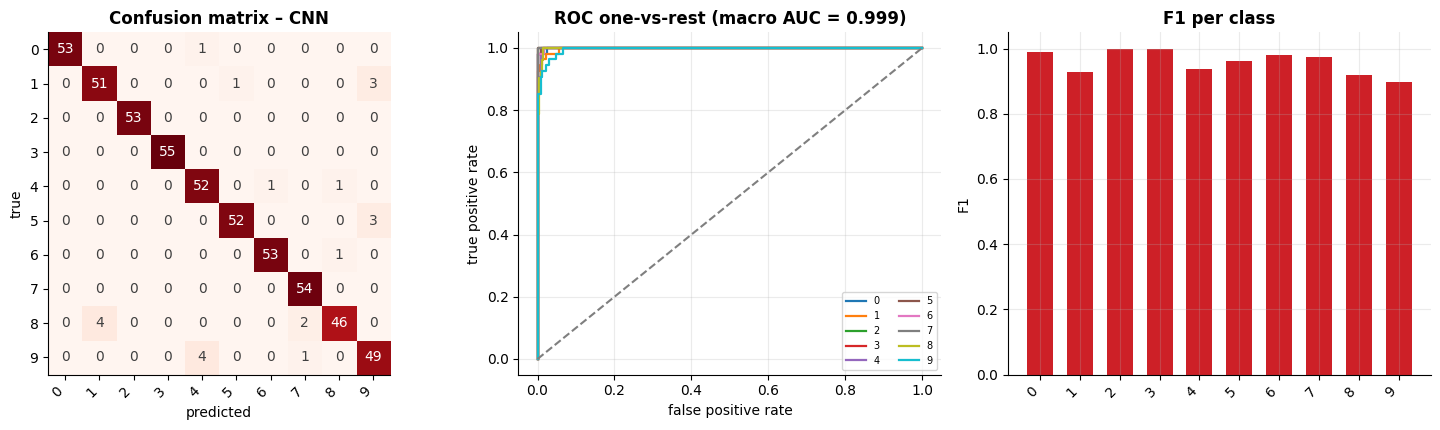

,accuracy,balanced acc.,macro precision,macro recall,macro F1,MCC,ROC AUC (ovr),log loss
CNN,0.959,0.959,0.96,0.959,0.959,0.955,0.999,0.132


In [20]:
#Evaluate the CNN on the Test Set
proba_cnn = cnn.predict_proba(imgs_te)
results["CNN"] = report_multiclass(y_te, proba_cnn.argmax(axis=1), proba_cnn, DIGITS, "CNN")
results["CNN"].to_frame().T

#### **CNN-Specific Metrics and Visualisations**

The **learned filters**, the **feature maps** for one image, and the **parameter efficiency / robustness to a 1-pixel shift** compared with the MLP.

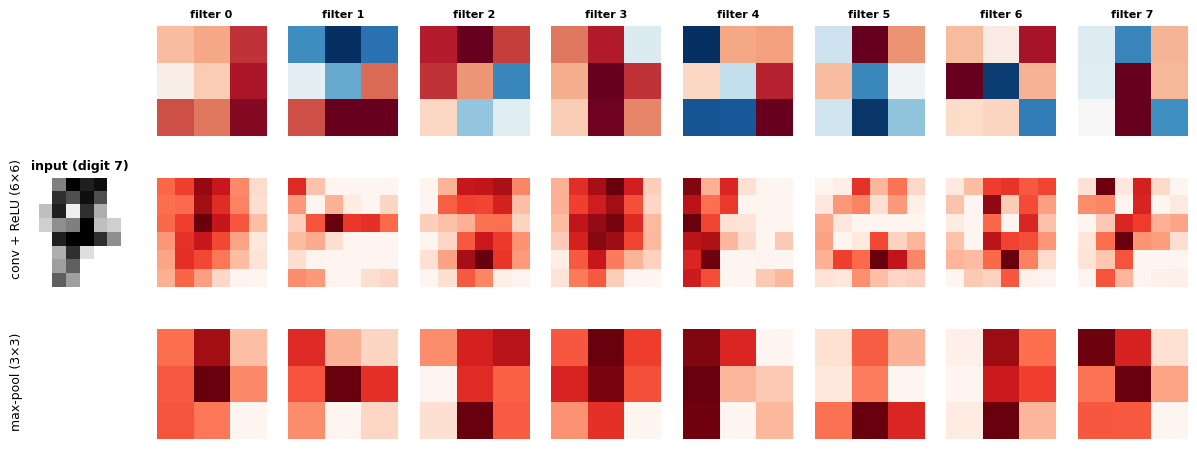

In [21]:
#Learned Filters and Feature Maps ( Convolution, ReLU, Pooling ) for One Test Digit
sample = 7
fil = cnn.p["Wc"].T.reshape(8, 3, 3)
cnn.forward(imgs_te[sample:sample + 1]); conv_out = np.maximum(cnn.cache[1][0], 0); pooled = cnn.cache[3][0]

fig = plt.figure(figsize=(15, 5.4))
gs = fig.add_gridspec(3, 9, hspace=0.35)
ax = fig.add_subplot(gs[0:3, 0]); ax.imshow(imgs_te[sample], cmap="gray_r"); ax.set_title(f"input (digit {y_te[sample]})", fontsize=9); ax.axis("off")
for f in range(8):
    a = fig.add_subplot(gs[0, f + 1]); a.imshow(fil[f], cmap="RdBu_r", vmin=-1, vmax=1); a.axis("off"); a.set_title(f"filter {f}", fontsize=8)
    b = fig.add_subplot(gs[1, f + 1]); b.imshow(conv_out[:, :, f], cmap="Reds"); b.axis("off")
    c = fig.add_subplot(gs[2, f + 1]); c.imshow(pooled[:, :, f], cmap="Reds"); c.axis("off")
fig.text(0.115, 0.52, "conv + ReLU (6×6)", fontsize=9, rotation=90, va="center"); fig.text(0.115, 0.22, "max-pool (3×3)", fontsize=9, rotation=90, va="center")
plt.show()

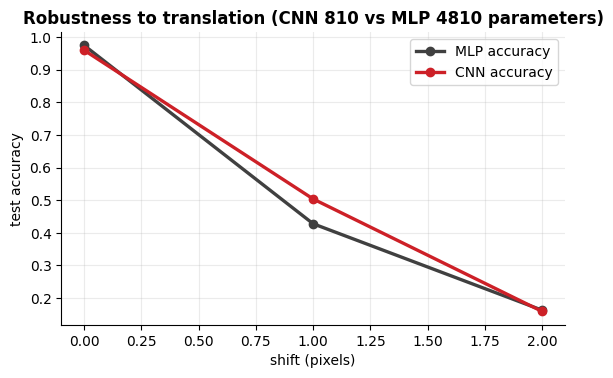

,MLP accuracy,CNN accuracy
shift (pixels),,
0,0.974,0.959
1,0.428,0.504
2,0.163,0.159


In [22]:
#Parameter Efficiency and Robustness: Accuracy on Test Images Shifted by 0, 1 and 2 Pixels ( MLP vs CNN, Trained on Unshifted Images )
rows = []
for shift in [0, 1, 2]:
    sh = np.roll(imgs_te, shift, axis=2)
    acc_cnn = (cnn.predict_proba(sh).argmax(axis=1) == y_te).mean()
    acc_mlp = (mlp.predict(sh.reshape(len(sh), -1)) == y_te).mean()
    rows.append({"shift (pixels)": shift, "MLP accuracy": acc_mlp, "CNN accuracy": acc_cnn})
shift_df = pd.DataFrame(rows).set_index("shift (pixels)")
shift_df.plot(marker="o", color=[DARK, RED], lw=2.4, figsize=(6.5, 3.8)); plt.ylabel("test accuracy"); plt.title(f"Robustness to translation (CNN {cnn.n_params()} vs MLP {n_params} parameters)")
plt.show()
shift_df.round(3)

This **tiny** CNN is only slightly more robust than the MLP to a 1-pixel (circular) shift and neither survives 2 pixels: translation invariance needs **more pooling / depth** or **data augmentation**, not just convolution.

### **7. LSTM (Long Short-Term Memory)**

A **recurrent** network with a **memory cell** $c_t$ controlled by **gates**:

$$f_t,\, i_t,\, o_t = \sigma(\cdot) \qquad g_t = \tanh(\cdot) \qquad c_t = f_t \odot c_{t-1} + i_t \odot g_t \qquad h_t = o_t \odot \tanh(c_t)$$

* **forget gate** $f$: what to erase · **input gate** $i$: what to write · **output gate** $o$: what to expose
* Trained by **backpropagation through time (BPTT)** with **gradient clipping**

Task: **forecast the next value** of a noisy series from the last 20 values. The first 80 % is used for training and the last 20 % (the *future*) for testing.

train windows: (944, 20, 1) | test windows: (236, 20, 1) | noise standard deviation: 0.05


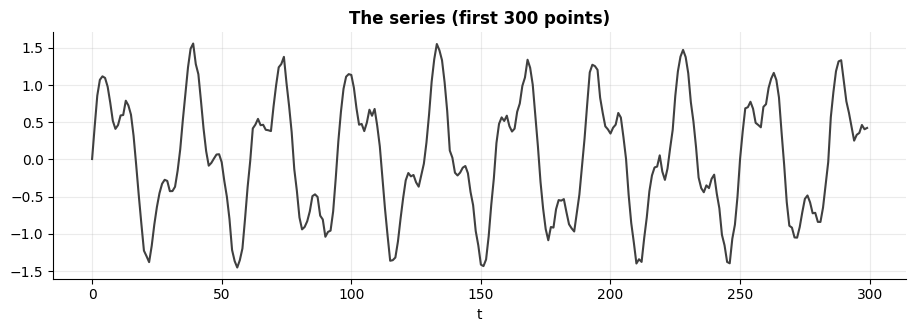

In [23]:
#Time Series ( Two Sinusoids + Noise ), Windows of 20 Steps and a Chronological Split
T = 20
t_axis = np.arange(1200)
series = np.sin(0.2 * t_axis) + 0.5 * np.sin(0.53 * t_axis) + 0.05 * np.random.default_rng(0).normal(size=len(t_axis))
Xw = np.array([series[i:i + T] for i in range(len(series) - T)])[:, :, None]
yw = series[T:].reshape(-1, 1)
n_tr = int(0.8 * len(Xw))
Xs_tr, ys_tr, Xs_te, ys_te = Xw[:n_tr], yw[:n_tr], Xw[n_tr:], yw[n_tr:]
print("train windows:", Xs_tr.shape, "| test windows:", Xs_te.shape, "| noise standard deviation: 0.05")
plt.figure(figsize=(11, 3.2)); plt.plot(t_axis[:300], series[:300], color=DARK, lw=1.5); plt.xlabel("t"); plt.title("The series (first 300 points)"); plt.show()

In [24]:
#LSTM from Scratch ( Gates, Memory Cell, BPTT, Gradient Clipping, Adam )
class LSTM:
    def __init__(self, n_in, H, seed=0):
        rng, self.H = np.random.default_rng(seed), H
        s = 1 / np.sqrt(H)
        self.p = {"Wx": rng.normal(0, s, (n_in, 4 * H)), "Wh": rng.normal(0, s, (H, 4 * H)), "b": np.zeros(4 * H), "Wy": rng.normal(0, s, (H, 1)), "by": np.zeros(1)}
        self.p["b"][H:2 * H] = 1.0                                                              # forget-gate bias = 1 (remember by default)
        self.m = {k: np.zeros_like(v) for k, v in self.p.items()}; self.v = {k: np.zeros_like(v) for k, v in self.p.items()}; self.t = 0

    def forward(self, X):
        B, T_, _ = X.shape; H, p = self.H, self.p
        h, c = np.zeros((B, H)), np.zeros((B, H))
        self.cache, self.gates = [], []
        for t in range(T_):
            z = X[:, t] @ p["Wx"] + h @ p["Wh"] + p["b"]
            i, f, o, g = expit(z[:, :H]), expit(z[:, H:2 * H]), expit(z[:, 2 * H:3 * H]), np.tanh(z[:, 3 * H:])
            c_new = f * c + i * g
            tc = np.tanh(c_new)
            self.cache.append((X[:, t], h, c, i, f, o, g, tc)); self.gates.append((i, f, o))
            h, c = o * tc, c_new
        self.h_last = h
        return h @ p["Wy"] + p["by"]

    def backward(self, dy):                                                                     # backpropagation through time
        p = self.p
        g_ = {k: np.zeros_like(v) for k, v in p.items()}
        g_["Wy"], g_["by"] = self.h_last.T @ dy, dy.sum(axis=0)
        dh = dy @ p["Wy"].T
        dc = np.zeros_like(dh)
        for (x, h_prev, c_prev, i, f, o, g, tc) in reversed(self.cache):
            do = dh * tc
            dc = dc + dh * o * (1 - tc ** 2)
            dz = np.concatenate([dc * g * i * (1 - i), dc * c_prev * f * (1 - f), do * o * (1 - o), dc * i * (1 - g ** 2)], axis=1)
            g_["Wx"] += x.T @ dz; g_["Wh"] += h_prev.T @ dz; g_["b"] += dz.sum(axis=0)
            dh, dc = dz @ p["Wh"].T, dc * f
        self.grads = g_

    def step(self, lr=0.005, clip=1.0):
        norm = np.sqrt(sum((g ** 2).sum() for g in self.grads.values()))
        scale = min(1.0, clip / (norm + 1e-12))                                                 # gradient clipping
        self.t += 1
        for k in self.p:
            g = self.grads[k] * scale
            self.m[k] = 0.9 * self.m[k] + 0.1 * g; self.v[k] = 0.999 * self.v[k] + 0.001 * g * g
            self.p[k] -= lr * (self.m[k] / (1 - 0.9 ** self.t)) / (np.sqrt(self.v[k] / (1 - 0.999 ** self.t)) + 1e-8)

    def n_params(self):
        return sum(v.size for v in self.p.values())

#Gradient Check of the BPTT
rng = np.random.default_rng(1)
Xc, yc = rng.normal(size=(4, 6, 1)), rng.normal(size=(4, 1))
chk = LSTM(1, 5, seed=3)
loss_fn = lambda: 0.5 * np.mean((chk.forward(Xc) - yc) ** 2)
chk.backward((chk.forward(Xc) - yc) / len(yc))
worst = 0.0
for k in chk.p:
    for _ in range(6):
        idx = tuple(rng.integers(s) for s in chk.p[k].shape); old = chk.p[k][idx]
        chk.p[k][idx] = old + 1e-6; lp = loss_fn(); chk.p[k][idx] = old - 1e-6; lm = loss_fn(); chk.p[k][idx] = old
        num, ana = (lp - lm) / 2e-6, chk.grads[k][idx]
        worst = max(worst, abs(num - ana) / max(1e-8, abs(num) + abs(ana)))
print(f"LSTM gradient check – worst relative error: {worst:.1e}")

LSTM gradient check – worst relative error: 4.0e-06


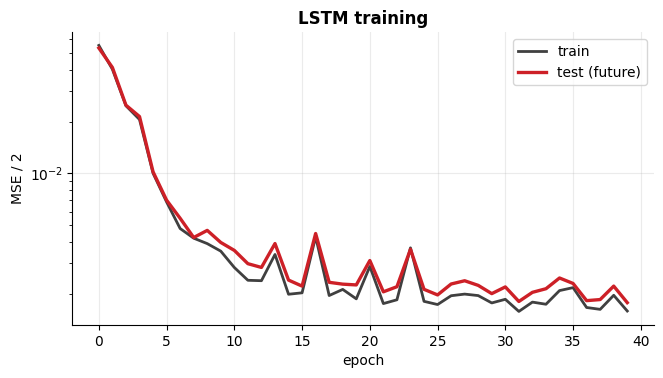

LSTM parameters: 1169


In [25]:
#Train the LSTM ( 16 Hidden Units, 40 Epochs )
lstm = LSTM(1, 16, seed=0)
rng = np.random.default_rng(0)
hist_lstm = {"train": [], "test": []}
for epoch in range(40):
    perm = rng.permutation(n_tr)
    for k in range(0, n_tr, 32):
        b = perm[k:k + 32]
        out = lstm.forward(Xs_tr[b]); lstm.backward((out - ys_tr[b]) / len(b)); lstm.step()
    hist_lstm["train"].append(0.5 * np.mean((lstm.forward(Xs_tr) - ys_tr) ** 2)); hist_lstm["test"].append(0.5 * np.mean((lstm.forward(Xs_te) - ys_te) ** 2))
plt.figure(figsize=(7.5, 3.8)); plt.plot(hist_lstm["train"], color=DARK, lw=2, label="train"); plt.plot(hist_lstm["test"], color=RED, lw=2.4, label="test (future)")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE / 2"); plt.title("LSTM training"); plt.legend(); plt.show()
print("LSTM parameters:", lstm.n_params())

,RMSE,MAE,R²
persistence (last value),0.245,0.203,0.904
linear AR(20),0.058,0.046,0.995
LSTM (16 units),0.060,0.048,0.994


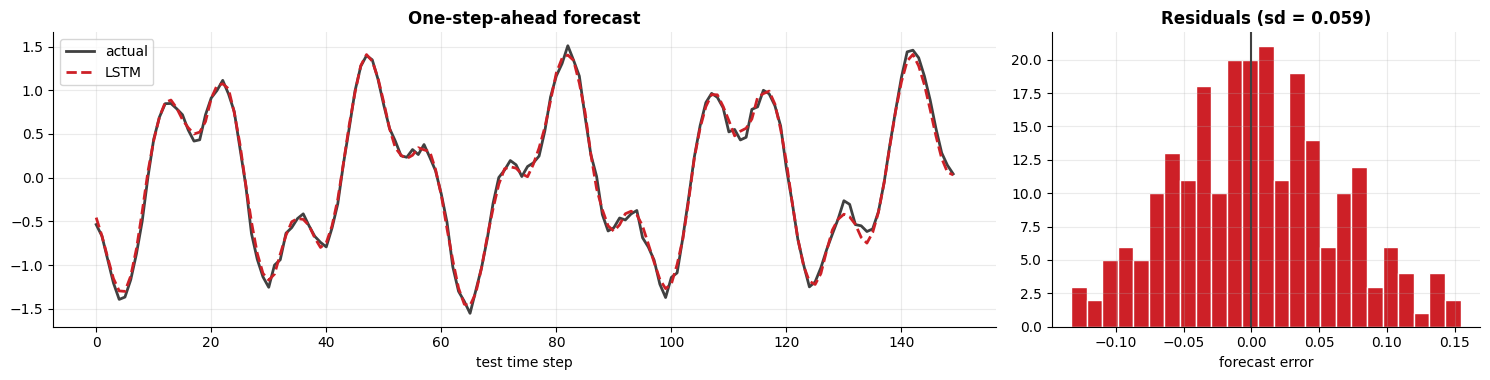

In [26]:
#Forecast Metrics vs Baselines ( Persistence and Linear Autoregression ) and the Forecast Plot
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred_lstm = lstm.forward(Xs_te).ravel()
ar = LinearRegression().fit(Xs_tr[:, :, 0], ys_tr.ravel())
preds = {"persistence (last value)": Xs_te[:, -1, 0], "linear AR(20)": ar.predict(Xs_te[:, :, 0]), "LSTM (16 units)": pred_lstm}
y_true_s = ys_te.ravel()
table = pd.DataFrame({name: {"RMSE": np.sqrt(mean_squared_error(y_true_s, p)), "MAE": mean_absolute_error(y_true_s, p), "R²": r2_score(y_true_s, p)} for name, p in preds.items()}).T
display(table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 3.9), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].plot(y_true_s[:150], color=DARK, lw=2, label="actual"); axes[0].plot(pred_lstm[:150], color=RED, lw=2, ls="--", label="LSTM"); axes[0].set_xlabel("test time step"); axes[0].set_title("One-step-ahead forecast"); axes[0].legend()
axes[1].hist(y_true_s - pred_lstm, bins=25, color=RED, edgecolor="white"); axes[1].axvline(0, color=DARK); axes[1].set_xlabel("forecast error"); axes[1].set_title(f"Residuals (sd = {np.std(y_true_s - pred_lstm):.3f})")
plt.tight_layout(); plt.show()

The LSTM reaches an error close to the **noise floor** (0.05), far below the persistence baseline. Since this series is a **sum of sinusoids**, a **linear** autoregression is also excellent: LSTMs pay off when the dynamics are **non-linear** or the memory is **long**.

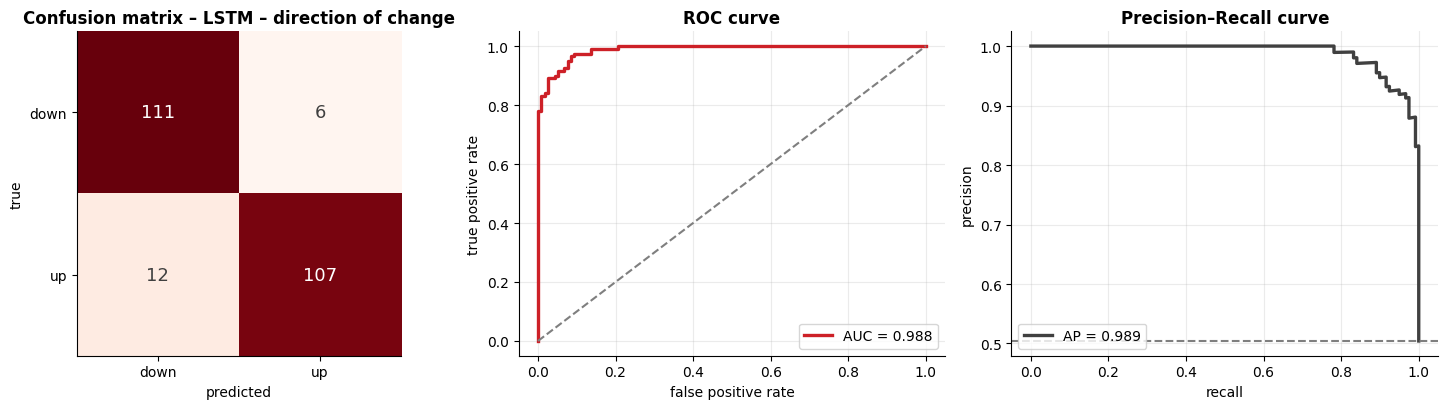

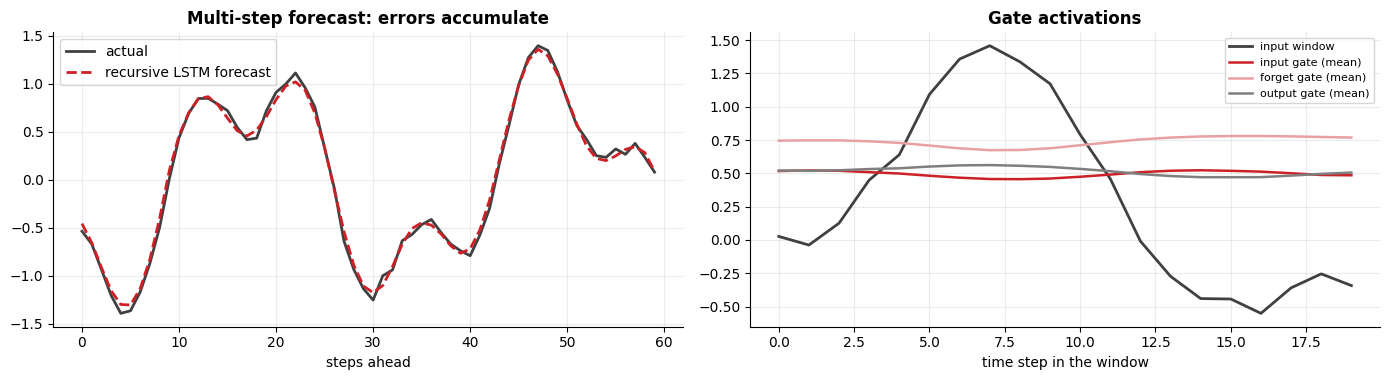

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
LSTM – direction of change,0.924,0.924,0.947,0.899,0.922,0.849,0.988,0.989


In [27]:
#Multi-Step Forecast ( Feeding the Predictions Back ), Direction-of-Change Classification and the Gates Inside the LSTM
window = list(Xs_te[0, :, 0]); true_future = series[n_tr + T:n_tr + T + 60]
rolled = []
for _ in range(60):
    nxt = float(lstm.forward(np.array(window[-T:])[None, :, None])[0, 0]); rolled.append(nxt); window.append(nxt)

up_true = (y_true_s > Xs_te[:, -1, 0]).astype(int)
res_dir = report_binary(up_true, (pred_lstm > Xs_te[:, -1, 0]).astype(int), pred_lstm - Xs_te[:, -1, 0], "LSTM – direction of change", ["down", "up"])

lstm.forward(Xs_te[:1])
gi, gf, go = [np.array([g[k][0].mean() for g in lstm.gates]) for k in range(3)]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
axes[0].plot(true_future, color=DARK, lw=2, label="actual"); axes[0].plot(rolled, color=RED, lw=2, ls="--", label="recursive LSTM forecast"); axes[0].set_xlabel("steps ahead"); axes[0].set_title("Multi-step forecast: errors accumulate"); axes[0].legend()
axes[1].plot(Xs_te[0, :, 0], color=DARK, lw=2, label="input window"); axes[1].plot(gi, color=RED, lw=1.8, label="input gate (mean)"); axes[1].plot(gf, color=SOFT, lw=1.8, label="forget gate (mean)"); axes[1].plot(go, color=GRAY, lw=1.8, label="output gate (mean)")
axes[1].set_xlabel("time step in the window"); axes[1].set_title("Gate activations"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
res_dir.to_frame().T

### **8. Generative Adversarial Network (GAN)**

Two networks play a **minimax game**:

$$\min_G \max_D \; \mathbb{E}_{x \sim p_{\text{data}}}[\log D(x)] + \mathbb{E}_{z \sim p_z}[\log(1 - D(G(z)))]$$

* **Generator $G$:** turns noise $z$ into fake samples · **Discriminator $D$:** tells real from fake
* In practice $G$ maximises $\log D(G(z))$ (*non-saturating* loss)
* At the equilibrium $D(x) = 0.5$ and the discriminator loss is $2\ln 2 \approx 1.386$

A **1-D** example: real data come from **two Gaussians** (modes at −2 and +2). It is easy to see **what the generator learns** and whether it suffers **mode collapse** (covering only one mode).

In [28]:
#GAN from Scratch ( Generator and Discriminator are MLPs with Hand-Written Backpropagation, Adam )
from scipy.stats import wasserstein_distance, ks_2samp

class Net:
    def __init__(self, sizes, seed=0):
        rng = np.random.default_rng(seed)
        self.W = [rng.normal(0, np.sqrt(2 / (a + b)), (a, b)) for a, b in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros(b) for b in sizes[1:]]
        self.m = [np.zeros_like(q) for q in self.W + self.b]; self.v = [np.zeros_like(q) for q in self.W + self.b]; self.t = 0

    def forward(self, x):
        self.cache = [x]
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            x = x @ W + b
            if i < len(self.W) - 1:
                x = np.tanh(x)
            self.cache.append(x)
        return x

    def backward(self, dout):
        gW, gb, d = [None] * len(self.W), [None] * len(self.W), dout
        for i in reversed(range(len(self.W))):
            if i < len(self.W) - 1:
                d = d * (1 - self.cache[i + 1] ** 2)
            gW[i], gb[i] = self.cache[i].T @ d, d.sum(axis=0)
            d = d @ self.W[i].T
        self.grads = gW + gb
        return d                                                                                # gradient w.r.t. the input

    def step(self, lr=1e-3, b1=0.5, b2=0.999):
        self.t += 1
        for k, (q, g) in enumerate(zip(self.W + self.b, self.grads)):
            self.m[k] = b1 * self.m[k] + (1 - b1) * g; self.v[k] = b2 * self.v[k] + (1 - b2) * g * g
            q -= lr * (self.m[k] / (1 - b1 ** self.t)) / (np.sqrt(self.v[k] / (1 - b2 ** self.t)) + 1e-8)

def bce_logits(logits, target):                                                                  # loss and its gradient w.r.t. the logits
    return np.mean(np.logaddexp(0, logits) - target * logits), (expit(logits) - target) / len(logits)

MODES, SD = (-2.0, 2.0), 0.5
def real_batch(rng, n):
    return np.where(rng.random(n) < 0.5, rng.normal(MODES[0], SD, n), rng.normal(MODES[1], SD, n)).reshape(-1, 1)

ZDIM, BATCH, STEPS = 2, 128, 6000
rng = np.random.default_rng(RANDOM_STATE)
G, D = Net([ZDIM, 16, 16, 1], seed=1), Net([1, 16, 16, 1], seed=2)
ref = real_batch(np.random.default_rng(999), 4000).ravel()                                       # large real sample for the metrics
z_fixed = np.random.default_rng(5).normal(size=(4000, ZDIM))
log = {"D loss": [], "G loss": [], "step": [], "W1": [], "KS": [], "share of negative mode": []}
snapshots = {}
for s in range(STEPS):
    xr, z = real_batch(rng, BATCH), rng.normal(size=(BATCH, ZDIM))
    xf = G.forward(z)
    l_r, g_r = bce_logits(D.forward(xr), np.ones((BATCH, 1))); D.backward(g_r); g1 = D.grads
    l_f, g_f = bce_logits(D.forward(xf), np.zeros((BATCH, 1))); D.backward(g_f); D.grads = [a + b for a, b in zip(g1, D.grads)]; D.step()      # discriminator step
    z = rng.normal(size=(BATCH, ZDIM)); xf = G.forward(z)
    l_g, g_g = bce_logits(D.forward(xf), np.ones((BATCH, 1))); dx = D.backward(g_g); G.backward(dx); G.step()                                  # generator step (non-saturating)
    log["D loss"].append(l_r + l_f); log["G loss"].append(l_g)
    if s % 100 == 0 or s == STEPS - 1:
        gen = G.forward(z_fixed).ravel()
        log["step"].append(s); log["W1"].append(wasserstein_distance(gen, ref)); log["KS"].append(ks_2samp(gen, ref).statistic); log["share of negative mode"].append((gen < 0).mean())
        if s in (0, 300, 1000, 3000, STEPS - 1):
            snapshots[s] = gen
print(f"final Wasserstein-1 distance: {log['W1'][-1]:.3f} | KS statistic: {log['KS'][-1]:.3f} | share of samples in the negative mode: {log['share of negative mode'][-1]:.2f} (ideal 0.50)")

final Wasserstein-1 distance: 0.243 | KS statistic: 0.185 | share of samples in the negative mode: 0.51 (ideal 0.50)


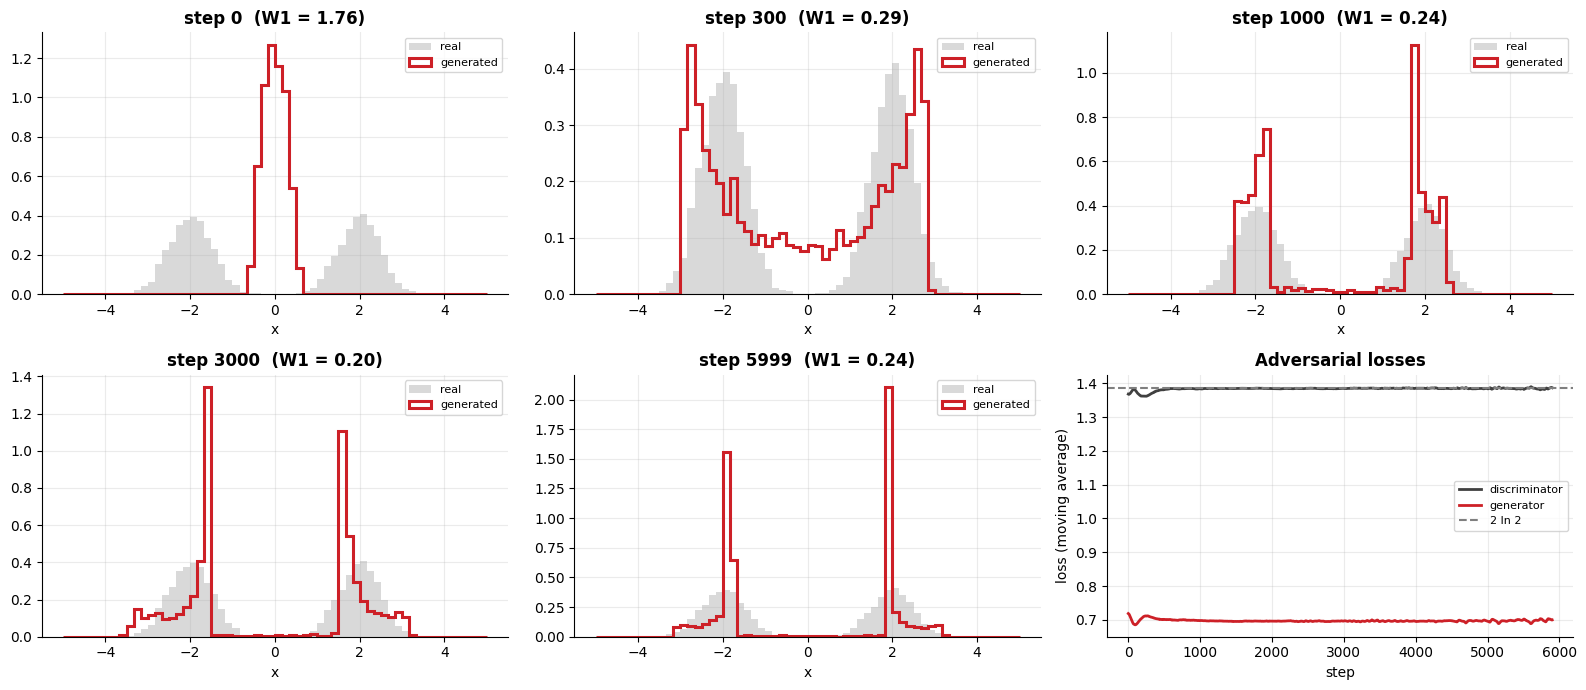

In [29]:
#What the Generator Learns: Distributions Along Training, Losses, and Distances to the Real Data
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, (s, gen) in zip(axes.ravel()[:5], snapshots.items()):
    ax.hist(ref, bins=60, range=(-5, 5), density=True, color=LIGHT, label="real"); ax.hist(gen, bins=60, range=(-5, 5), density=True, histtype="step", color=RED, lw=2.2, label="generated")
    ax.set_title(f"step {s}  (W1 = {wasserstein_distance(gen, ref):.2f})"); ax.set_xlabel("x"); ax.legend(fontsize=8)
sm = lambda a, k=100: np.convolve(a, np.ones(k) / k, mode="valid")
axes[1, 2].plot(sm(log["D loss"]), color=DARK, lw=2, label="discriminator"); axes[1, 2].plot(sm(log["G loss"]), color=RED, lw=2, label="generator"); axes[1, 2].axhline(2 * np.log(2), color=GRAY, ls="--", label="2 ln 2")
axes[1, 2].set_xlabel("step"); axes[1, 2].set_ylabel("loss (moving average)"); axes[1, 2].set_title("Adversarial losses"); axes[1, 2].legend(fontsize=8)
plt.tight_layout(); plt.show()

#### **GAN-Specific Metrics**

There is **no accuracy** to maximise, so a GAN is judged by **how close** the generated distribution is to the real one:

* **Wasserstein-1** and **Kolmogorov–Smirnov** distances (lower is better) and the **mode coverage / balance**
* **Discriminability:** an independent classifier trained to separate real from generated data – **AUC ≈ 0.5** means the fakes are hard to detect

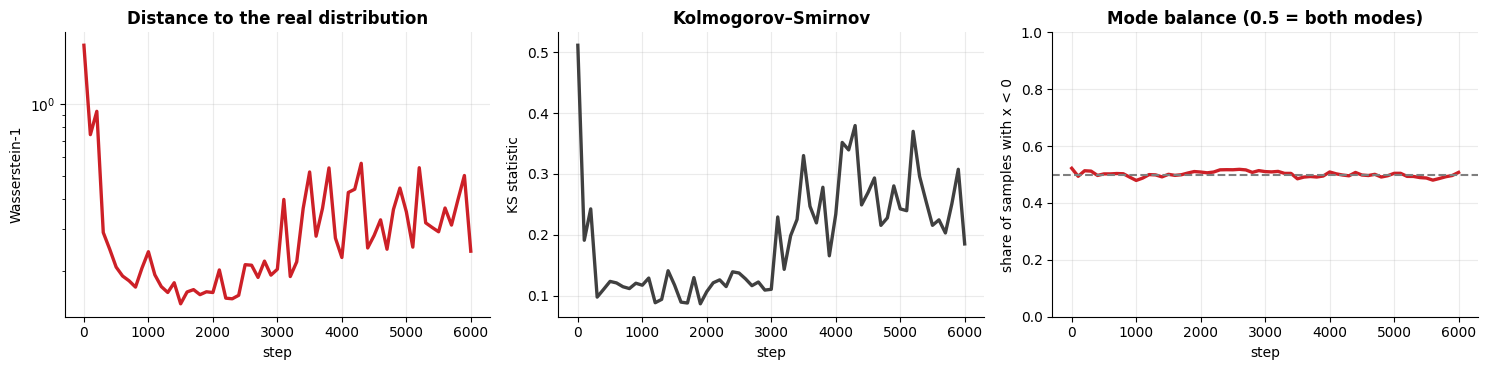

samples within 3 SD of each mode: 0.505 (mode -2) and 0.490 (mode +2) | outside both modes: 0.005
generated mean/sd: -0.01/2.05 | real mean/sd: -0.05/2.05


In [30]:
#Distances Along Training and Mode Coverage
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(log["step"], log["W1"], color=RED, lw=2.4); axes[0].set_yscale("log"); axes[0].set_xlabel("step"); axes[0].set_ylabel("Wasserstein-1"); axes[0].set_title("Distance to the real distribution")
axes[1].plot(log["step"], log["KS"], color=DARK, lw=2.4); axes[1].set_xlabel("step"); axes[1].set_ylabel("KS statistic"); axes[1].set_title("Kolmogorov–Smirnov")
axes[2].plot(log["step"], log["share of negative mode"], color=RED, lw=2.4); axes[2].axhline(0.5, color=GRAY, ls="--"); axes[2].set_ylim(0, 1); axes[2].set_xlabel("step"); axes[2].set_ylabel("share of samples with x < 0"); axes[2].set_title("Mode balance (0.5 = both modes)")
plt.tight_layout(); plt.show()

gen_final = G.forward(z_fixed).ravel()
cover = [np.mean(np.abs(gen_final - m) < 3 * SD) for m in MODES]
print(f"samples within 3 SD of each mode: {cover[0]:.3f} (mode -2) and {cover[1]:.3f} (mode +2) | outside both modes: {1 - sum(cover):.3f}")
print(f"generated mean/sd: {gen_final.mean():.2f}/{gen_final.std():.2f} | real mean/sd: {ref.mean():.2f}/{ref.std():.2f}")

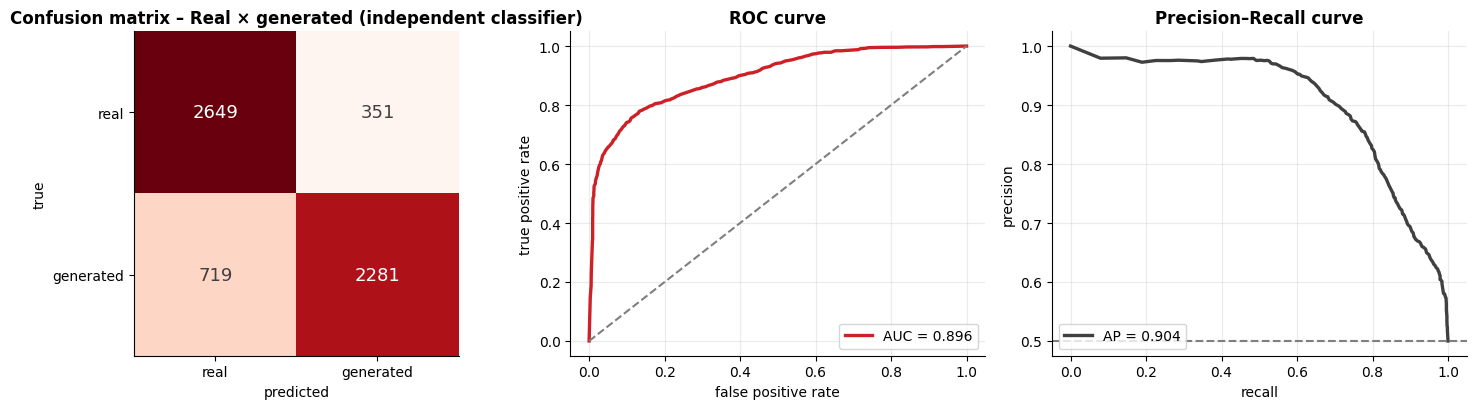

the GAN's own discriminator: mean D(real) = 0.50, mean D(generated) = 0.50 (0.5 = cannot tell)


,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
Real × generated (independent classifier),0.822,0.822,0.867,0.76,0.81,0.648,0.896,0.904


In [31]:
#Can an Independent Classifier Tell Real from Generated Samples? ( Confusion Matrix, ROC, Precision-Recall )
from sklearn.ensemble import HistGradientBoostingClassifier

gen_a = G.forward(np.random.default_rng(11).normal(size=(3000, ZDIM))); gen_b = G.forward(np.random.default_rng(12).normal(size=(3000, ZDIM)))
real_a, real_b = real_batch(np.random.default_rng(13), 3000), real_batch(np.random.default_rng(14), 3000)
clf = HistGradientBoostingClassifier(random_state=RANDOM_STATE).fit(np.vstack([real_a, gen_a]), np.r_[np.zeros(3000), np.ones(3000)])
Xtest_gan, ytest_gan = np.vstack([real_b, gen_b]), np.r_[np.zeros(3000), np.ones(3000)]
p_fake = clf.predict_proba(Xtest_gan)[:, 1]
res_gan = report_binary(ytest_gan, (p_fake > 0.5).astype(int), p_fake, "Real × generated (independent classifier)", ["real", "generated"])
d_out = expit(D.forward(Xtest_gan))
print(f"the GAN's own discriminator: mean D(real) = {d_out[ytest_gan == 0].mean():.2f}, mean D(generated) = {d_out[ytest_gan == 1].mean():.2f} (0.5 = cannot tell)")
res_gan.to_frame().T

Both discriminator outputs are ≈ 0.50 (the game is at its equilibrium), yet an **independent** classifier still separates real from generated samples (AUC ≈ 0.90): the generated density is **close but not identical** (W₁ ≈ 0.24): in the histograms the generated peaks are **narrower** than the real ones. The discriminator's own loss is **not** a quality measure – use **independent distances and tests**.

### **9. Summary**

,accuracy,balanced acc.,macro F1,MCC,ROC AUC (ovr),log loss,parameters,supervised?
MLP,0.974,0.974,0.974,0.971,0.999,0.100,4810,yes
SOM,0.922,0.922,0.922,0.914,0.990,0.318,6400,no (labels only to name the neurons)
CNN,0.959,0.959,0.959,0.955,0.999,0.132,810,yes


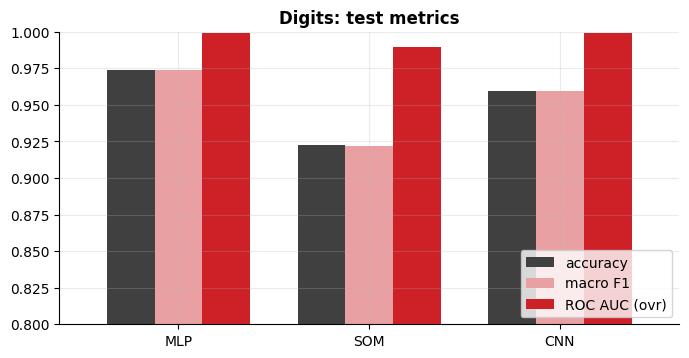

In [32]:
#Test-Set Comparison of the Classifying Networks on the Digits ( MLP, SOM, CNN ) and the Parameters Each One Uses
comp = pd.DataFrame(results).T[["accuracy", "balanced acc.", "macro F1", "MCC", "ROC AUC (ovr)", "log loss"]]
comp["parameters"] = [n_params, 100 * 64, cnn.n_params()]
comp["supervised?"] = ["yes", "no (labels only to name the neurons)", "yes"]
display(comp.round(3))
comp[["accuracy", "macro F1", "ROC AUC (ovr)"]].plot.bar(color=[DARK, SOFT, RED], figsize=(8, 3.8), rot=0, width=0.75); plt.ylim(0.8, 1.0); plt.title("Digits: test metrics"); plt.legend(loc="lower right")
plt.show()

| | **MLP** | **SOM** | **Hopfield** | **CNN** | **LSTM** | **GAN** |
|---|---|---|---|---|---|---|
| Data | tabular | any vectors | binary patterns | images / grids | sequences | any distribution |
| Strength | universal approximator | unsupervised **map** | content-addressable memory | few parameters, local features | memory of the past | realistic samples |
| Main risk | overfitting | choice of grid / radius | low capacity (≈ 0.14 N) | needs data and tuning | vanishing/exploding gradients | **unstable training, mode collapse** |
| Specific metrics | loss curves, capacity | QE, TE, U-matrix | recall × noise, energy | filters, shift robustness | RMSE, baselines, gates | W₁, KS, mode coverage |
| Frameworks | `sklearn`, Keras, PyTorch | `minisom` | – | Keras, PyTorch | Keras, PyTorch | Keras, PyTorch |